Task 1,2,3 and 4: Develop the GridEnv Class

In [3]:
import numpy as np
import gymnasium as gym
from matplotlib import pyplot as plt 

**Defining environment for RL (Reinforcement Learning)**
<br>
- The key idea: GridEnv defines the world and its rules
- don't implement the learning algorithm inside GridEnv itself—that belongs to the agent or training loop.

In [4]:
# Define a custom Grid Environment, inherited from gym.Env
class GridEnv(gym.Env):
    def __init__(self, square_grid_size=5):
        self.size = square_grid_size

    def reset(self):
        # state -> agent position (x, y)
        self.state = (0, 0)
        self.total_reward = 0

    '''
    Two function of step():
        1. Update the agent's state based on the action taken.
        2. Determine the reward and whether the episode is done based on the new state.
    '''
    def step(self, action):

        if action == 0 and self.state[0] > 0:  # Up
            self.state = (self.state[0] - 1, self.state[1])
        elif action == 1 and self.state[0] < self.size - 1:  # Down
            self.state = (self.state[0] + 1, self.state[1])
        elif action == 2 and self.state[1] > 0:  # Left
            self.state = (self.state[0], self.state[1] - 1)
        elif action == 3 and self.state[1] < self.size - 1:  # Right
            self.state = (self.state[0], self.state[1] + 1)

        if self.state == (self.size - 1, self.size - 1):
            reward = 50
        elif self.state == (self.size - 1, 0):
            reward = -50
        else:
            reward = -1

        done = self.state == (self.size-1, self.size-1) or self.state == (self.size-1, 0)

        return self.state, reward, done



Task 5: Train the Agent

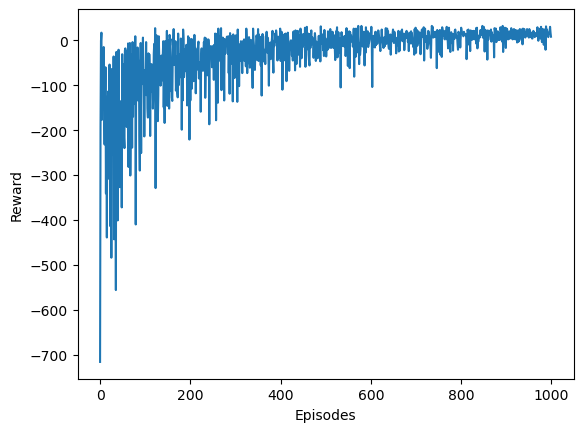

In [12]:
from Agent import Agent

if __name__ == "__main__":
    env = GridEnv(square_grid_size=10)

    '''
    PARAMETERS:
    - gamma: determines how much importance is given to future rewards.
        Closer to 1: the agent will consider future rewards more heavily -> Optimize long-term rewards
    - lr: Learning rate for updating the Q-values.
    - n_actions: Number of possible actions the agent can take.
    - eps_dec: Rate at which the exploration rate (epsilon) decays.
        higher value: slower decay, allowing more exploration for longer as training progresses
    - eps_start: Initial exploration rate (epsilon) at the start of training.
        epsilon at 1.0: the agent will initially make decisions purely based on exploration, choosing actions randomly.

        EXTRA CONCEPTS: 
        Epsilon: The rate of exploration vs. exploitation in reinforcement learning.
    '''
    agent = Agent(gamma=0.995, lr=0.01, n_actions=4, eps_dec=0.9, eps_start=1.0, eps_end=0.01)

    n_episodes = 1000

    # To store each epsiode's total reward for plotting later
    scores = []

    for episode in range(n_episodes):
        done = False
        state = env.reset()
        score = 0

        while not done:
            action = agent.choose_actions(state)
            next_state, reward, done = env.step(action)
            agent.learn(state, action, reward, next_state)
            score += reward
            state = next_state

        scores.append(score)


    # The plot: The learning curve of the agent's performance over episodes, showing how the total reward changes as the agent learns.
    plt.plot(scores)     
    plt.xlabel('Episodes')
    plt.ylabel('Reward')
